In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import random
import sys

sys.path.append("../../../mapqc/")
import mapqc
import plotting

In [2]:
query_batch = "Sheppard_2020"

In [3]:
kl_parameter = 0.1

In [4]:
adata = sc.read_h5ad(f"./{query_batch}_kl{kl_parameter}/combined_embedding_klweight_{kl_parameter}.h5ad")

In [5]:
ref_q_key = "core_or_extension"
ref_cat = "core"
query_cat = "extension"
batch_key = "dataset"
sample_key = "sample"
condition_key = "condition"
coi = "NML"
emb_key = "X"

In [6]:
adata

AnnData object with n_obs × n_vars = 664964 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'tis

In [7]:
print(f"Subsetting query to condition {coi}")
adata_healthy = adata[
    (adata.obs[ref_q_key] == ref_cat)
    | (adata.obs[condition_key] == coi)
].copy()

Subsetting query to condition NML


In [8]:
print("number of query samples left:", len(adata_healthy.obs.loc[adata_healthy.obs[ref_q_key] == query_cat, 'sample'].unique()))

number of query samples left: 6


In [9]:
adata.shape

(664964, 30)

In [10]:
adata_healthy.shape

(612730, 30)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


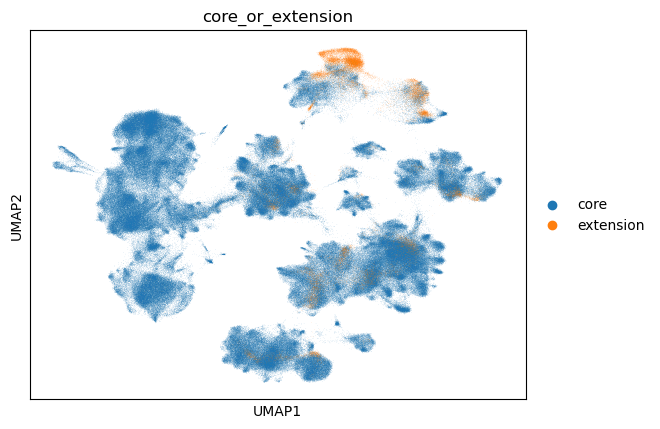

In [11]:
sc.pl.umap(adata_healthy, color=ref_q_key)

#### run MapQC:

In [12]:
n_nhoods = 300
k = int((adata.obs[ref_q_key] == ref_cat).sum() / 200)
max_k = int(k * 1.2)

In [13]:
print(f"k: {k}, max k: {max_k}")

k: 2924, max k: 3508


In [14]:
query_cell_idc_healthy = np.where(adata_healthy.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_healthy = random.sample(query_cell_idc_healthy, k=n_nhoods)
center_cells_healthy = np.array(adata_healthy.obs.iloc[center_cell_idc_healthy, :].index)

In [15]:
results_healthy = mapqc.mapQC_results(
    adata=adata_healthy,
    center_cells=center_cells_healthy,
    k=k,
    emb_key=emb_key,
    ref_q_key=ref_q_key,
    ref_cat=ref_cat,
    query_cat=query_cat,
    batch_key=batch_key,
    exclude_same_batch_for_ref_samples=True,
    use_adaptive_k=True,
    max_k=max_k,
    min_n_samples_q=1 # not the default!
)

In [16]:
results_healthy.calculate_sample_dists_to_ref_samples()

300it [09:03,  1.81s/it]

79% of neighborhoods passed filtering. (For more details, see [mapqc_object]._nhood_filtered)



../../../mapqc/mapqc.py:199: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
../../../mapqc/mapqc.py:203: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [17]:
results_healthy._nhood_filtered.value_counts()

pass                                                237
too few reference samples                            32
too few reference samples from different batches     29
too few query samples                                 2
dtype: int64

In [18]:
results_healthy.calculate_nhood_statistics(q=66)

77% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.
For 49% of filtered neighborhoods, >34% of samples are more than two standard deviations above the mean distance from the reference.
33% of query samples (2 sample(s)) consistently do not mix well with the reference.
If these are control samples, consider removing them from the query and re-mapping.
For more information, check .sample_median_dist_to_ref_across_nhoods
or run plotting.plot_sample_distances_to_reference.


../../../mapqc/mapqc.py:341: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,


In [19]:
results_healthy.calculate_cell_statistics_from_nhoods_using_nhood_stats()

Percentage of query cells in low-mixing neighborhoods: 59.97 (cutoff percentile: 66).


In [20]:
results_healthy.calculate_cell_statistics_using_sample_level_results_per_nhood()

Percentage of query cells showing low sample-mixing: 58.42.


### Plot

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


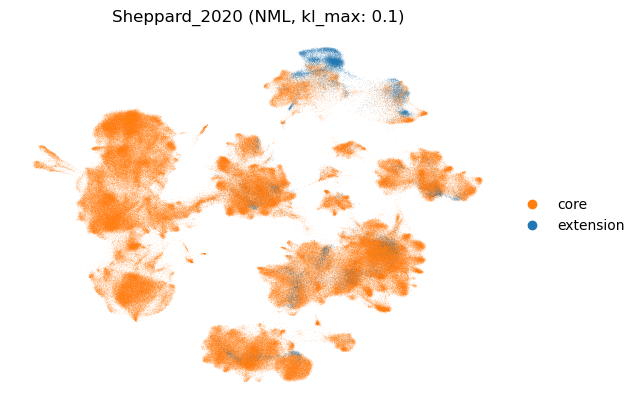

In [18]:
sc.pl.umap(
    results_healthy.adata,
    color=ref_q_key,
    palette={
        results_healthy.ref_cat: "tab:orange",
        results_healthy.query_cat: "tab:blue",
    },
    title=f"{query_batch} ({coi}, kl_max: {kl_parameter})",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


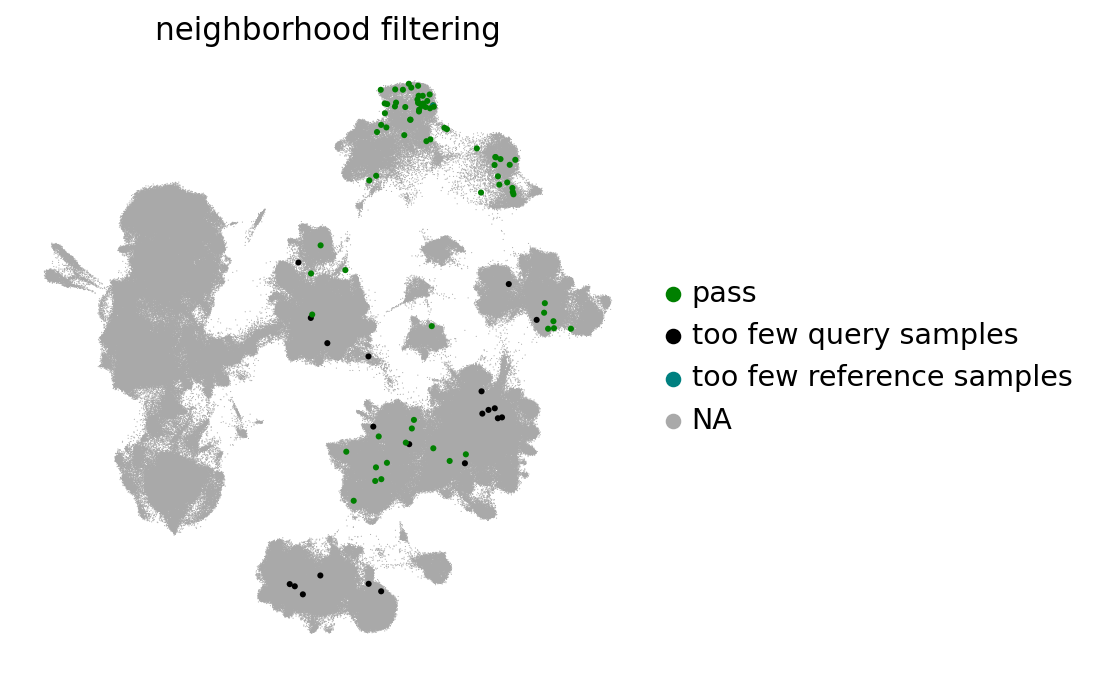

In [19]:
plotting.plot_umap_filtering_info(results_healthy)

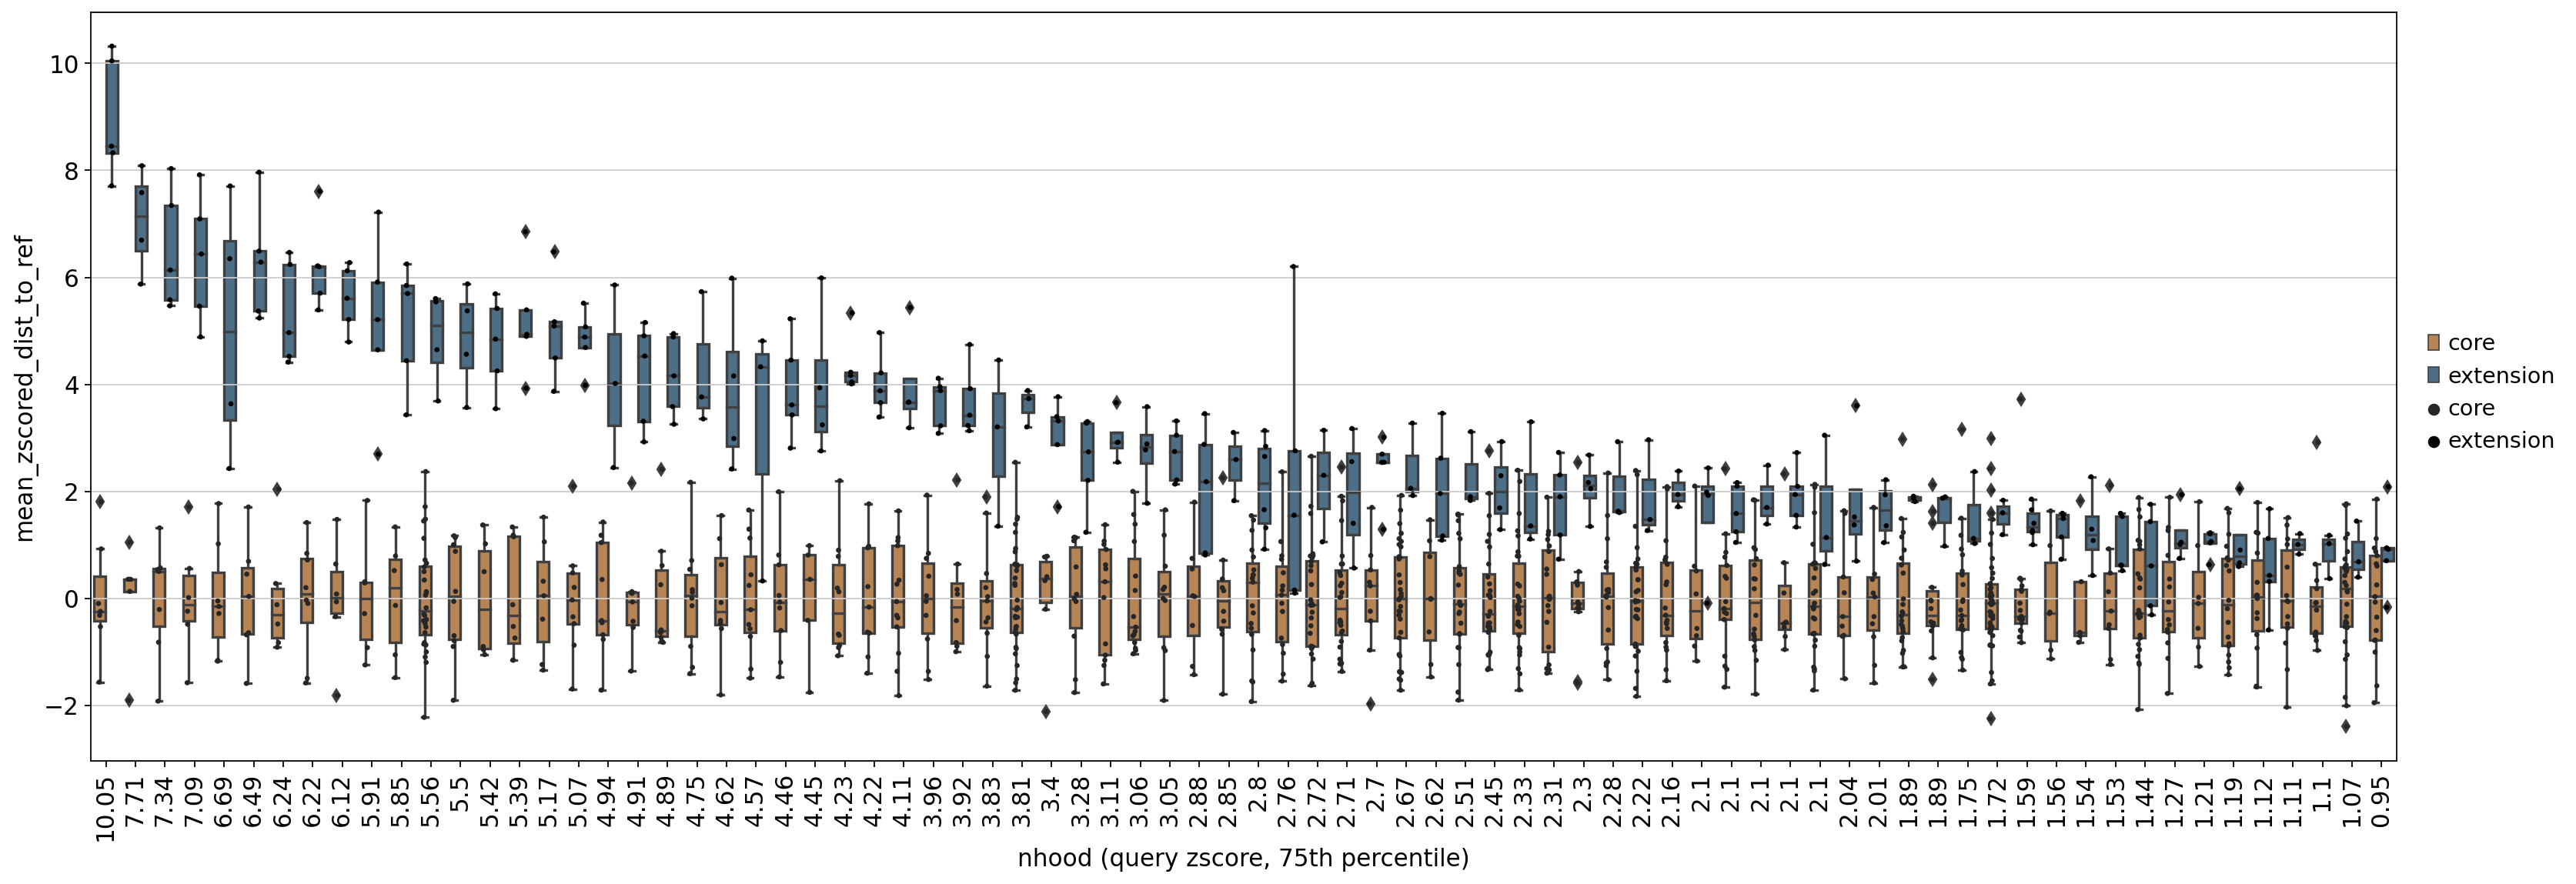

In [20]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(results_healthy, use_zscored_dists=True)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


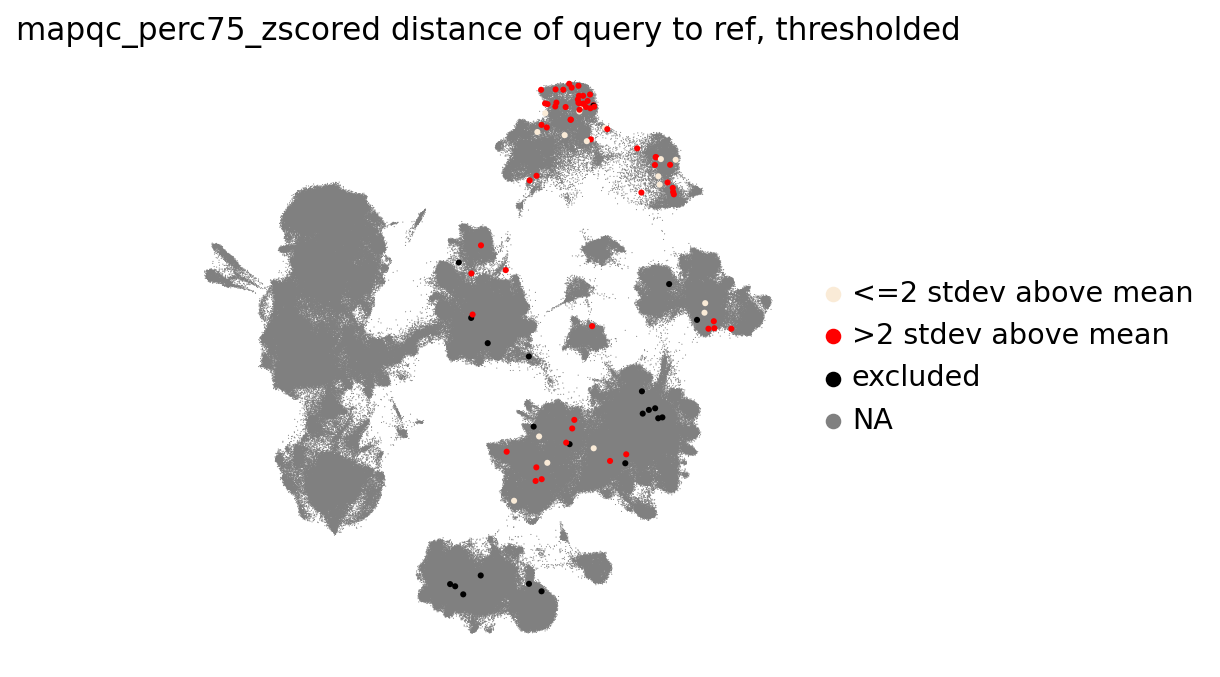

In [21]:
plotting.plot_umap_zscored_q_dist_to_ref(results_healthy, color_by="percq_zscore>2")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


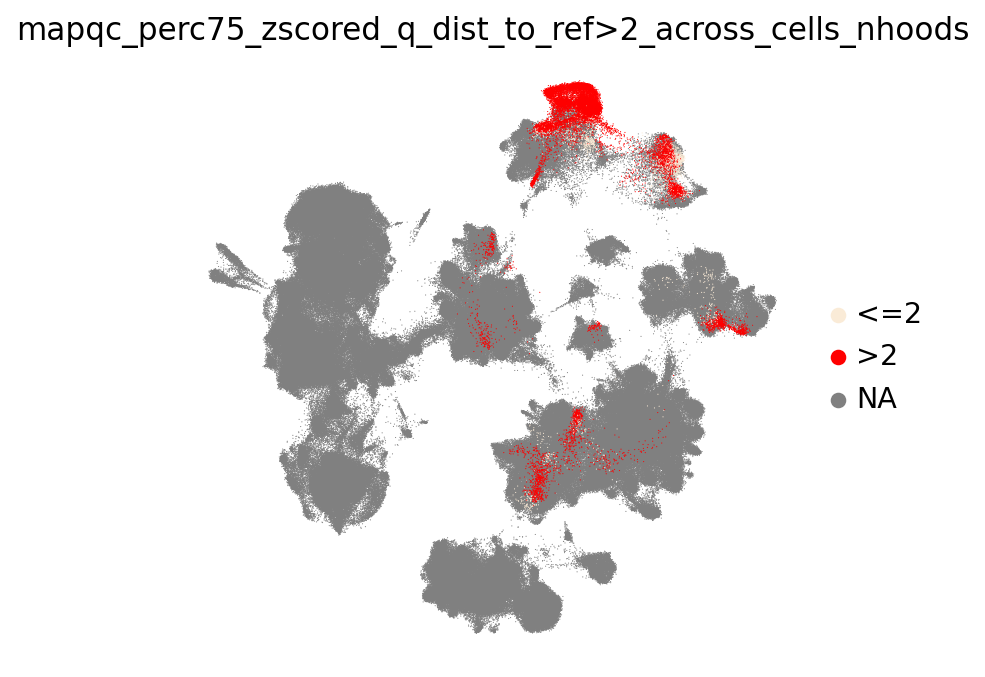

In [22]:
plotting.plot_umap_cell_level_results(results_healthy, size=1)

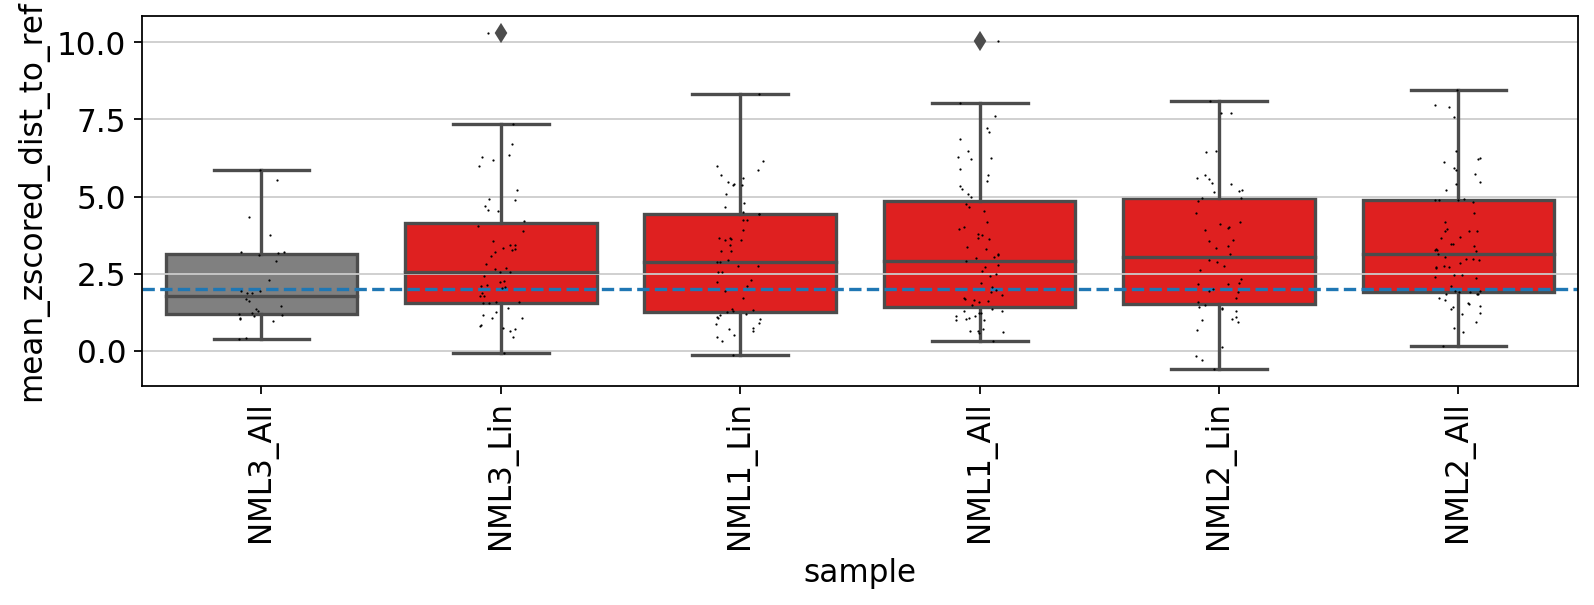

In [23]:
plotting.plot_sample_distances_to_reference(results_healthy)